Loading I-JEPA...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding images...
  labrador: decay=0.87, dim=1280
  cat: decay=1.45, dim=1280
  person: decay=1.23, dim=1280
  cute_dog: decay=1.10, dim=1280

Running ORIGINAL (unnormalized replay)...
  Replay fired 154 times
Running FIXED (normalized replay)...
  Replay fired 154 times

COMPARISON: ORIGINAL vs NORMALIZED REPLAY

Final Activations:
  Memory         Original       Normalized     Decay α   
  labrador       0.000000       0.049097       0.87      
  cat            0.000000       0.030218       1.45      
  person         0.146975       0.035070       1.23      
  cute_dog       0.000000       0.039555       1.10      

Late Replay Weights (last 10%):
  Original (unnormalized):
    labrador      : 0.0000
    cat           : 0.0000
    person        : 1.0000
    cute_dog      : 0.0000
  Normalized:
    labrador      : 0.2511
    cat           : 0.2466
    person        : 0.2491
    cute_dog      : 0.2532

Surviving memories: Original=1/4, Normalized=4/4


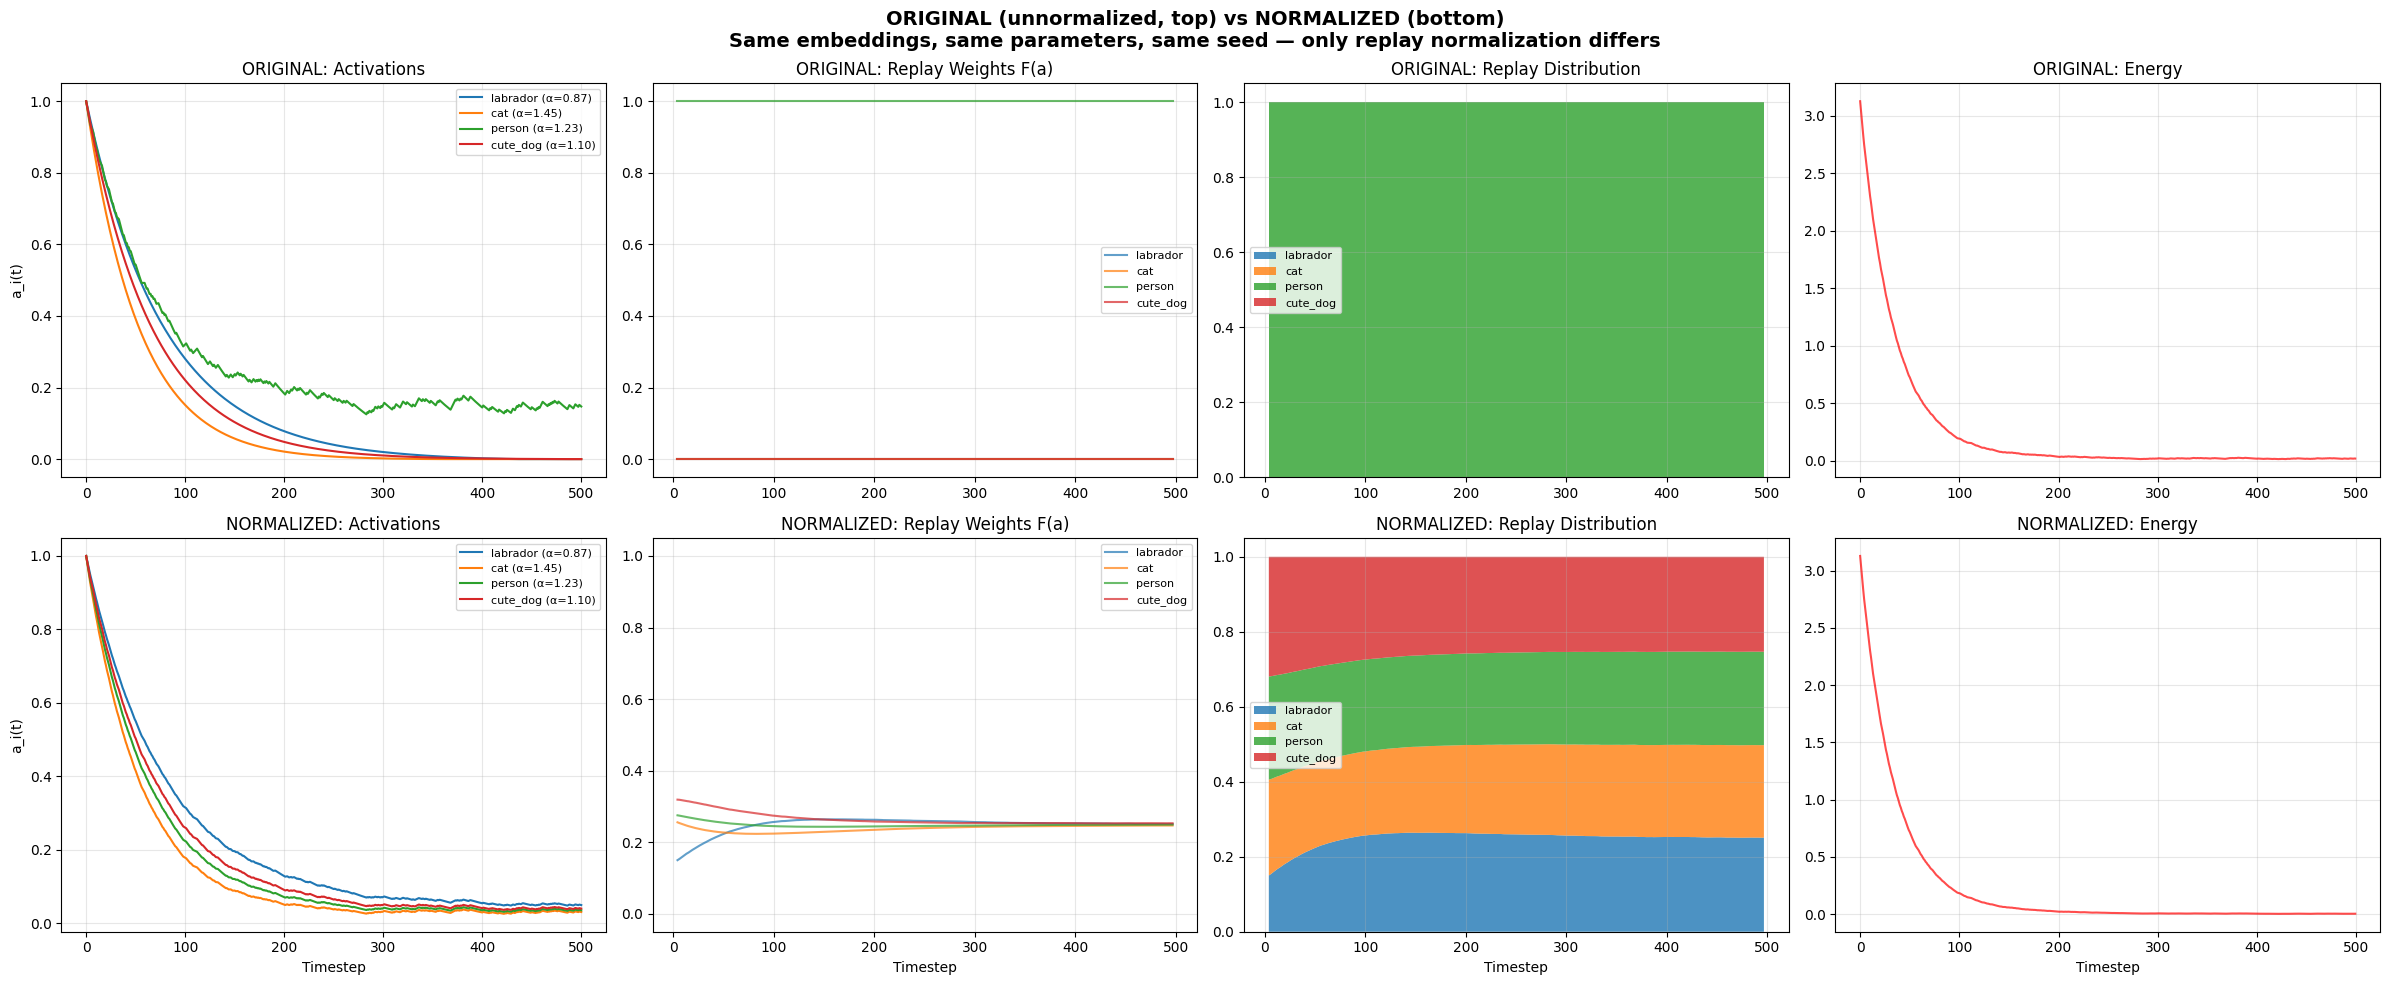


VERDICT
✅ Normalizing replay scores recovered the balanced regime.
   Original: 1/4 survived → Normalized: 4/4 survived
   The paper's framework works with real embeddings once scores are normalized.


In [ ]:
# ============================================================
# OPTION A: NORMALIZED REPLAY — Does balanced regime emerge?
# Same setup as Run 1, but F(a) uses normalized embeddings
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Load I-JEPA
model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA...")
processor = AutoProcessor.from_pretrained(model_id)
encoder = AutoModel.from_pretrained(model_id).eval()

@torch.no_grad()
def encode_image(url):
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers, stream=True, timeout=15)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content)).convert("RGB")
    inputs = processor(img, return_tensors="pt")
    outputs = encoder(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze()

# Same Unsplash URLs as your original notebook
urls = [
    "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400",
    "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400",
    "https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400",
    "https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400"
]
labels = ["labrador", "cat", "person", "cute_dog"]

# ============================================================
# Two versions of DynamicalMemory — original vs normalized
# ============================================================
class DynamicalMemoryComparison:
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01,
                 normalize_replay=False):
        self.embeddings = []
        self.activations = None
        self.gamma = gamma
        self.delta = delta
        self.beta = beta
        self.eta = eta
        self.h = h
        self.decay_rates = []
        self.normalize_replay = normalize_replay  # THE ONE DIFFERENCE

    def store(self, embedding, decay_rate=1.0):
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        N = len(self.embeddings)
        if self.activations is None:
            self.activations = torch.ones(N)
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)
        W.fill_diagonal_(0)
        D = torch.diag(W.sum(dim=1))
        return D - W

    def _replay_operator(self):
        X = torch.stack(self.embeddings)
        if self.normalize_replay:
            # FIXED: normalize before computing scores
            X_n = F.normalize(X, dim=1)
            s = X_n @ (X_n.T @ self.activations)
        else:
            # ORIGINAL: raw unnormalized dot products
            s = X @ (X.T @ self.activations)
        return F.softmax(self.beta * s, dim=0), s

    def run_tracked(self, steps=500, replay_prob=0.3):
        act_history = [self.activations.clone().numpy()]
        replay_weights = []
        replay_steps = []
        energies = []

        for t in range(steps):
            a = self.activations
            N = len(a)
            A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
            L = self._build_laplacian()

            f_decay = -A @ a
            f_diffusion = -self.gamma * L @ a
            f_inhibition = -self.delta * a.sum() * torch.ones(N)

            S = 1.0 if np.random.random() < replay_prob else 0.0
            Fa, raw_s = self._replay_operator()
            f_replay = self.eta * S * Fa

            if S > 0:
                replay_weights.append(Fa.detach().numpy().copy())
                replay_steps.append(t)

            da_dt = f_decay + f_diffusion + f_inhibition + f_replay
            self.activations = a + self.h * da_dt
            self.activations = torch.clamp(self.activations, min=0)
            act_history.append(self.activations.clone().numpy())

            e1 = 0.5 * a @ A @ a
            e2 = 0.5 * self.gamma * a @ L @ a
            e3 = 0.5 * self.delta * (a.sum())**2
            energies.append((e1 + e2 + e3).item())

        return {
            'activations': np.array(act_history),
            'replay_weights': np.array(replay_weights),
            'replay_steps': np.array(replay_steps),
            'energy': np.array(energies),
        }

# ============================================================
# Encode images once
# ============================================================
print("\nEncoding images...")
all_embeddings = []
all_decays = []
for url, label in zip(urls, labels):
    emb = encode_image(url)
    decay = np.random.uniform(0.5, 1.5)
    all_embeddings.append(emb)
    all_decays.append(decay)
    print(f"  {label}: decay={decay:.2f}, dim={emb.shape[0]}")

# ============================================================
# Run BOTH versions side by side
# ============================================================

# --- ORIGINAL (unnormalized) ---
torch.manual_seed(42)
np.random.seed(42)
mem_orig = DynamicalMemoryComparison(normalize_replay=False)
for emb, decay in zip(all_embeddings, all_decays):
    mem_orig.store(emb, decay)

torch.manual_seed(42)  # reset seed so replay gating is identical
np.random.seed(42)
print("\nRunning ORIGINAL (unnormalized replay)...")
res_orig = mem_orig.run_tracked(steps=500, replay_prob=0.3)
print(f"  Replay fired {len(res_orig['replay_steps'])} times")

# --- FIXED (normalized) ---
torch.manual_seed(42)
np.random.seed(42)
mem_norm = DynamicalMemoryComparison(normalize_replay=True)
for emb, decay in zip(all_embeddings, all_decays):
    mem_norm.store(emb, decay)

torch.manual_seed(42)
np.random.seed(42)
print("Running FIXED (normalized replay)...")
res_norm = mem_norm.run_tracked(steps=500, replay_prob=0.3)
print(f"  Replay fired {len(res_norm['replay_steps'])} times")

# ============================================================
# PRINT RESULTS
# ============================================================
print("\n" + "="*60)
print("COMPARISON: ORIGINAL vs NORMALIZED REPLAY")
print("="*60)

print("\nFinal Activations:")
print(f"  {'Memory':<14} {'Original':<14} {'Normalized':<14} {'Decay α':<10}")
for i, l in enumerate(labels):
    print(f"  {l:<14} {res_orig['activations'][-1][i]:<14.6f} {res_norm['activations'][-1][i]:<14.6f} {all_decays[i]:<10.2f}")

print("\nLate Replay Weights (last 10%):")
rw_o = res_orig['replay_weights']
rw_n = res_norm['replay_weights']
late_o = rw_o[-max(1, len(rw_o)//10):]
late_n = rw_n[-max(1, len(rw_n)//10):]

print("  Original (unnormalized):")
for i, l in enumerate(labels):
    print(f"    {l:<14}: {late_o[:,i].mean():.4f}")
print("  Normalized:")
for i, l in enumerate(labels):
    print(f"    {l:<14}: {late_n[:,i].mean():.4f}")

# Count survivors
orig_survivors = sum(1 for x in res_orig['activations'][-1] if x > 0.001)
norm_survivors = sum(1 for x in res_norm['activations'][-1] if x > 0.001)
print(f"\nSurviving memories: Original={orig_survivors}/4, Normalized={norm_survivors}/4")

# ============================================================
# PLOTS — side by side comparison
# ============================================================
fig, axes = plt.subplots(2, 4, figsize=(24, 10))

# Row 1: ORIGINAL
ax = axes[0][0]
for i, l in enumerate(labels):
    ax.plot(res_orig['activations'][:, i], label=f"{l} (α={all_decays[i]:.2f})")
ax.set_title("ORIGINAL: Activations"); ax.set_ylabel("a_i(t)"); ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[0][1]
rs_o = res_orig['replay_steps']
for i, l in enumerate(labels):
    ax.plot(rs_o, rw_o[:, i], label=l, alpha=0.7)
ax.set_title("ORIGINAL: Replay Weights F(a)"); ax.set_ylim(-0.05, 1.05)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[0][2]
step = max(1, len(rs_o) // 300)
ax.stackplot(rs_o[::step], [rw_o[::step, i] for i in range(4)],
             labels=labels, alpha=0.8)
ax.set_title("ORIGINAL: Replay Distribution"); ax.legend(fontsize=8, loc='center left')
ax.grid(True, alpha=0.3)

ax = axes[0][3]
ax.plot(res_orig['energy'], color='red', alpha=0.7)
ax.set_title("ORIGINAL: Energy"); ax.grid(True, alpha=0.3)

# Row 2: NORMALIZED
ax = axes[1][0]
for i, l in enumerate(labels):
    ax.plot(res_norm['activations'][:, i], label=f"{l} (α={all_decays[i]:.2f})")
ax.set_title("NORMALIZED: Activations"); ax.set_ylabel("a_i(t)"); ax.set_xlabel("Timestep")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[1][1]
rs_n = res_norm['replay_steps']
for i, l in enumerate(labels):
    ax.plot(rs_n, rw_n[:, i], label=l, alpha=0.7)
ax.set_title("NORMALIZED: Replay Weights F(a)"); ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Timestep"); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[1][2]
step = max(1, len(rs_n) // 300)
ax.stackplot(rs_n[::step], [rw_n[::step, i] for i in range(4)],
             labels=labels, alpha=0.8)
ax.set_title("NORMALIZED: Replay Distribution"); ax.set_xlabel("Timestep")
ax.legend(fontsize=8, loc='center left'); ax.grid(True, alpha=0.3)

ax = axes[1][3]
ax.plot(res_norm['energy'], color='red', alpha=0.7)
ax.set_title("NORMALIZED: Energy"); ax.set_xlabel("Timestep"); ax.grid(True, alpha=0.3)

fig.suptitle("ORIGINAL (unnormalized, top) vs NORMALIZED (bottom)\n"
             "Same embeddings, same parameters, same seed — only replay normalization differs",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("original_vs_normalized.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("VERDICT")
print("="*60)
if norm_survivors > orig_survivors:
    print(f"✅ Normalizing replay scores recovered the balanced regime.")
    print(f"   Original: {orig_survivors}/4 survived → Normalized: {norm_survivors}/4 survived")
    print(f"   The paper's framework works with real embeddings once scores are normalized.")
elif norm_survivors == orig_survivors:
    print(f"⚠️  Same number of survivors ({norm_survivors}/4). Normalization alone didn't change the outcome.")
else:
    print(f"❌ Normalized version had fewer survivors. Something else is going on.")